**Optimal Transport and Game Dynamics in Generative Adversarial Learning**

In [ ]:
"""
Optimal Transport and Game Dynamics in GANs -- image version (MNIST).

Scalar toy  ->  this script
---------------------------------------------------------------
payoff V(g,d)                 WGAN-GP minimax game  min_G max_D E[D(x)] - E[D(G(z))]
W1(Pg, Pr) = |g - mean|       Sliced Wasserstein-1 between generated and real images
path length of g(t)           sum of SW1 between consecutive generator snapshots
efficiency                    (SW0 - SW_T) / path length
eps convergence               eps = 1.5 x noise floor (real-vs-real SW1)
lr_g, lr_d regimes            same idea: different (lr_g, lr_d, n_critic) settings

Run:  pip install torch torchvision matplotlib numpy
      python gan_images_wasserstein_dynamics.py
Use a GPU (Colab T4 is fine). Set QUICK = True for a fast smoke test.
"""
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from torchvision import datasets, transforms
from torchvision.utils import make_grid

QUICK = False                      # True -> tiny run to check everything works
DATASET = "MNIST"                  # "MNIST" or "FashionMNIST"
SEED = 42
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

Z_DIM = 64
BATCH = 64
GP_LAMBDA = 10.0
G_STEPS = 300 if QUICK else 4000   # generator updates per regime
EVAL_EVERY = 50 if QUICK else 100
N_EVAL = 1000 if QUICK else 2000   # images used per snapshot
N_PROJ = 128                       # random projections for sliced Wasserstein

# (lr_g, lr_d, n_critic)
EXPERIMENTS = {
    "Balanced":            (1e-4, 1e-4, 5),
    "Fast critic (TTUR)":  (1e-4, 4e-4, 5),
    "Fast generator":      (4e-4, 1e-4, 1),
    "Aggressive (unstable)": (2e-3, 1e-4, 1),
}

torch.manual_seed(SEED)
np.random.seed(SEED)

# ---------------------------------------------------------------- data
tf = transforms.Compose([transforms.ToTensor(),
                         transforms.Normalize((0.5,), (0.5,))])   # -> [-1, 1]
DS = getattr(datasets, DATASET)
train_ds = DS("./data", train=True, download=True, transform=tf)
test_ds = DS("./data", train=False, download=True, transform=tf)

loader = torch.utils.data.DataLoader(train_ds, batch_size=BATCH, shuffle=True,
                                     drop_last=True, num_workers=2)


def take(ds, n, seed):
    idx = np.random.RandomState(seed).choice(len(ds), n, replace=False)
    return torch.stack([ds[i][0] for i in idx]).view(n, -1)


real_eval = take(test_ds, N_EVAL, 1).to(DEVICE)          # P_r reference
real_floor = take(train_ds, N_EVAL, 2).to(DEVICE)        # for noise floor

# ---------------------------------------------------------------- metric
proj_gen = torch.Generator(device="cpu").manual_seed(0)
PROJ = torch.randn(784, N_PROJ, generator=proj_gen)
PROJ = (PROJ / PROJ.norm(dim=0, keepdim=True)).to(DEVICE)


@torch.no_grad()
def sliced_w1(a, b):
    """Sliced Wasserstein-1 between two equal-size sets of flattened images."""
    pa = (a @ PROJ).sort(dim=0).values
    pb = (b @ PROJ).sort(dim=0).values
    return (pa - pb).abs().mean().item()


NOISE_FLOOR = sliced_w1(real_eval, real_floor)
EPS = 1.5 * NOISE_FLOOR
print(f"Device: {DEVICE} | noise floor SW1 = {NOISE_FLOOR:.4f} | eps = {EPS:.4f}")

# ---------------------------------------------------------------- models
class G(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc = nn.Sequential(nn.Linear(Z_DIM, 128 * 7 * 7), nn.ReLU(True))
        self.net = nn.Sequential(
            nn.ConvTranspose2d(128, 64, 4, 2, 1), nn.BatchNorm2d(64), nn.ReLU(True),
            nn.ConvTranspose2d(64, 1, 4, 2, 1), nn.Tanh())

    def forward(self, z):
        return self.net(self.fc(z).view(-1, 128, 7, 7))


class D(nn.Module):                    # critic: no BatchNorm (needed for GP)
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 64, 4, 2, 1), nn.LeakyReLU(0.2, True),
            nn.Conv2d(64, 128, 4, 2, 1), nn.LeakyReLU(0.2, True),
            nn.Flatten(), nn.Linear(128 * 7 * 7, 1))

    def forward(self, x):
        return self.net(x).view(-1)


def grad_penalty(d, real, fake):
    eps = torch.rand(real.size(0), 1, 1, 1, device=DEVICE)
    xh = (eps * real + (1 - eps) * fake).requires_grad_(True)
    g = torch.autograd.grad(d(xh).sum(), xh, create_graph=True)[0]
    return ((g.view(g.size(0), -1).norm(dim=1) - 1) ** 2).mean()


def infinite(loader):
    while True:
        for x, _ in loader:
            yield x


# ---------------------------------------------------------------- training
fixed_z = torch.randn(N_EVAL, Z_DIM, device=DEVICE)
sample_z = torch.randn(64, Z_DIM, device=DEVICE)


def train(lr_g, lr_d, n_critic):
    torch.manual_seed(SEED)
    g, d = G().to(DEVICE), D().to(DEVICE)
    og = torch.optim.Adam(g.parameters(), lr=lr_g, betas=(0.0, 0.9))
    od = torch.optim.Adam(d.parameters(), lr=lr_d, betas=(0.0, 0.9))
    data = infinite(loader)

    dists, snaps, w_est = [], [], []

    def snapshot():
        g.eval()
        with torch.no_grad():
            fake = g(fixed_z).view(N_EVAL, -1)
        g.train()
        dists.append(sliced_w1(fake, real_eval))
        snaps.append(fake)

    snapshot()
    for it in range(1, G_STEPS + 1):
        for _ in range(n_critic):                       # critic ascent
            real = next(data).to(DEVICE)
            z = torch.randn(BATCH, Z_DIM, device=DEVICE)
            fake = g(z).detach()
            w = d(real).mean() - d(fake).mean()          # critic's W1 estimate
            loss_d = -w + GP_LAMBDA * grad_penalty(d, real, fake)
            od.zero_grad(); loss_d.backward(); od.step()
        z = torch.randn(BATCH, Z_DIM, device=DEVICE)     # generator descent
        loss_g = -d(g(z)).mean()
        og.zero_grad(); loss_g.backward(); og.step()

        if it % EVAL_EVERY == 0:
            snapshot()
            w_est.append(w.item())
    g.eval()
    with torch.no_grad():
        grid = g(sample_z).cpu()
    return dists, snaps, w_est, grid


results = {}
for name, (lg, ld, nc) in EXPERIMENTS.items():
    print(f"Training: {name} (lr_g={lg}, lr_d={ld}, n_critic={nc})")
    dists, snaps, w_est, grid = train(lg, ld, nc)
    dists = np.array(dists)
    # path length in (sliced) Wasserstein space: consecutive generator snapshots
    steps_w = np.array([sliced_w1(snaps[i], snaps[i + 1]) for i in range(len(snaps) - 1)])
    path = steps_w.sum()
    eff = (dists[0] - dists[-1]) / path if path > 1e-12 else 0.0
    below = np.where(dists < EPS)[0]
    conv = int(below[0]) * EVAL_EVERY if len(below) else None
    worsen = int(np.sum(np.diff(dists) > 0))             # oscillation analogue
    results[name] = dict(dists=dists, path=path, eff=eff, conv=conv,
                         worsen=worsen, w_est=w_est, grid=grid,
                         lr_g=lg, lr_d=ld, nc=nc)
    del snaps

# ---------------------------------------------------------------- report
print("\nGAN GAME DYNAMICS ON IMAGES: RESULTS")
print(f"Dataset: {DATASET} | metric: sliced W1 | noise floor {NOISE_FLOOR:.4f} | eps {EPS:.4f}")
print("-" * 110)
print(f"{'Regime':<24}{'lr_g':>8}{'lr_d':>8}{'n_crit':>8}{'Init SW1':>10}"
      f"{'Final SW1':>11}{'Path len':>10}{'Efficiency':>11}{'Conv iter':>10}{'Worsen':>8}")
print("-" * 110)
for n, r in results.items():
    ct = str(r["conv"]) if r["conv"] is not None else "never"
    print(f"{n:<24}{r['lr_g']:>8.0e}{r['lr_d']:>8.0e}{r['nc']:>8d}"
          f"{r['dists'][0]:>10.4f}{r['dists'][-1]:>11.4f}{r['path']:>10.4f}"
          f"{r['eff']:>11.4f}{ct:>10}{r['worsen']:>8d}")

# ---------------------------------------------------------------- plots
xs = np.arange(len(next(iter(results.values()))["dists"])) * EVAL_EVERY

plt.figure(figsize=(10, 5))
for n, r in results.items():
    plt.semilogy(xs, r["dists"], label=n)
plt.axhline(EPS, color="gray", ls=":", label="eps")
plt.xlabel("Generator iteration"); plt.ylabel("Sliced W1(Pg, Pr)")
plt.title(f"Convergence of Generator Distribution ({DATASET})")
plt.legend(); plt.grid(alpha=0.3, which="both"); plt.tight_layout(); plt.show()

plt.figure(figsize=(10, 5))
for n, r in results.items():
    plt.plot(xs[1:], r["w_est"], label=n)
plt.xlabel("Generator iteration"); plt.ylabel("Critic Wasserstein estimate")
plt.title("Critic's W1 estimate (value of the game)")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

plt.figure(figsize=(7, 5))
for n, r in results.items():
    plt.scatter(r["path"], r["eff"], s=90, label=n)
plt.xlabel("Path length in Wasserstein space"); plt.ylabel("Efficiency")
plt.title("Trajectory length vs efficiency")
plt.legend(fontsize=8); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, len(results) + 1, figsize=(4 * (len(results) + 1), 4.4))
real_grid = make_grid(real_eval[:64].view(-1, 1, 28, 28).cpu(), nrow=8, normalize=True, value_range=(-1, 1))
axes[0].imshow(real_grid.permute(1, 2, 0)); axes[0].set_title("Real"); axes[0].axis("off")
for ax, (n, r) in zip(axes[1:], results.items()):
    gr = make_grid(r["grid"], nrow=8, normalize=True, value_range=(-1, 1))
    ax.imshow(gr.permute(1, 2, 0)); ax.set_title(n, fontsize=9); ax.axis("off")
plt.tight_layout(); plt.show()

print("\nLIMITATION: SW1 is a projection-based approximation of W1 in pixel space; "
      "a feature-space metric (e.g. Inception/FID features) would be a stronger check.")

100%|██████████| 9.91M/9.91M [00:00<00:00, 45.4MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.13MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 10.3MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 10.6MB/s]


Device: cpu | noise floor SW1 = 0.0251 | eps = 0.0377
Training: Balanced (lr_g=0.0001, lr_d=0.0001, n_critic=5)
Training: Fast critic (TTUR) (lr_g=0.0001, lr_d=0.0004, n_critic=5)


GAN GAME DYNAMICS: EXPERIMENTAL RESULTS
Payoff: V(g,d) = gd - (gamma/2)d^2, gamma = 1.2
Equilibrium: (g*, d*) = (0, 0)
----------------------------------------------------------------------------------------------------------------
Regime                     lr_g   lr_d      rho     Final W1     Path len  Efficiency   Conv iter  Crossings
----------------------------------------------------------------------------------------------------------------
Stable                     0.08   0.10   0.9423    3.208e-06       1.7626      0.8510          26          4
Oscillatory (damped)       1.00   0.20   0.9798    2.658e-02      29.2847      0.0503          57         29
Oscillatory (marginal)     1.20   0.20   1.0000    1.682e+00     139.7296     -0.0013       never         32
Unstable                   1.50   0.20   1.0296    8.194e+02    9669.7677     -0.0846          30         35

Eigenvalues of the update matrix:
Stable                  [0.94+0.0663j 0.94-0.0663j] |lambda|max = 0.9423
Os

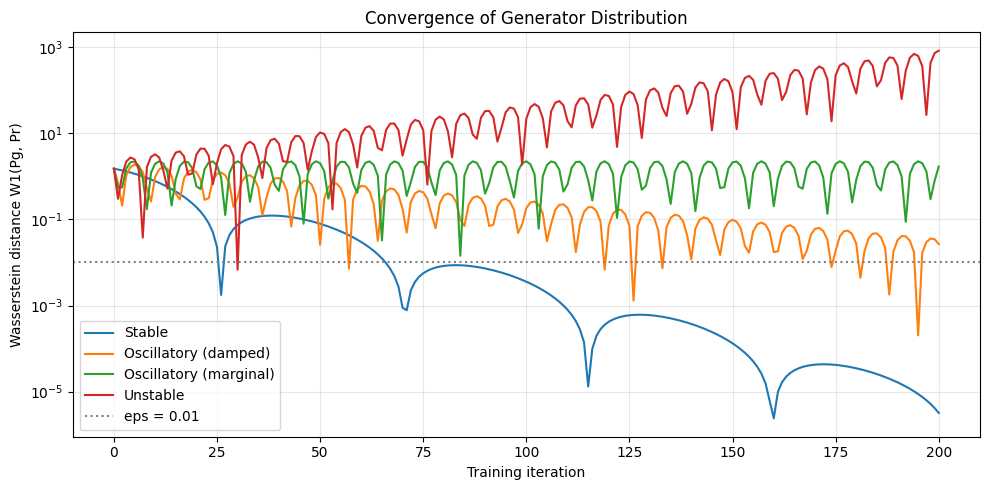

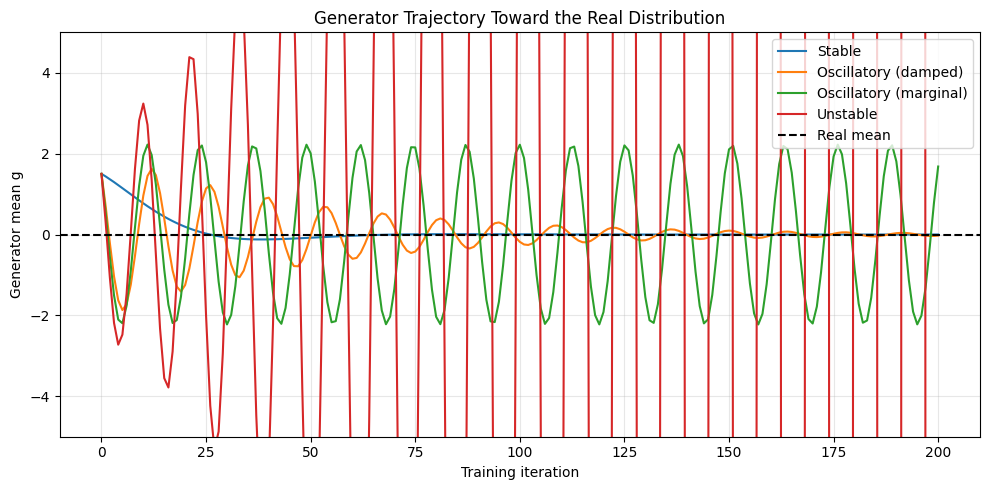

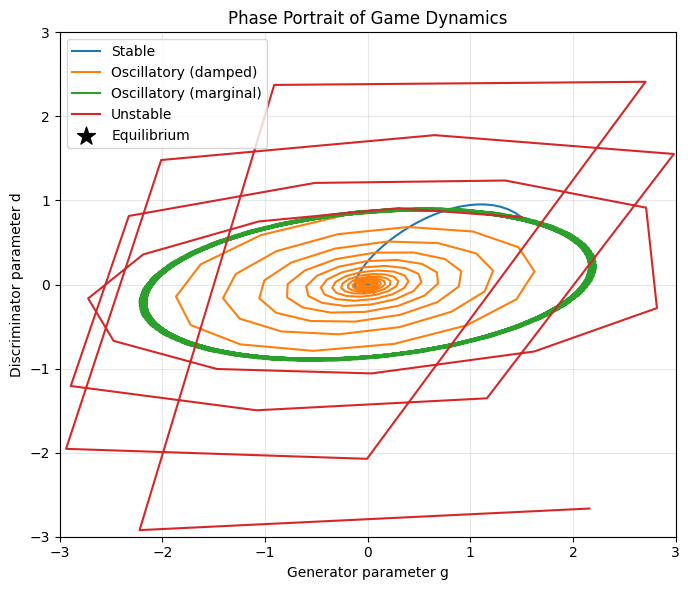

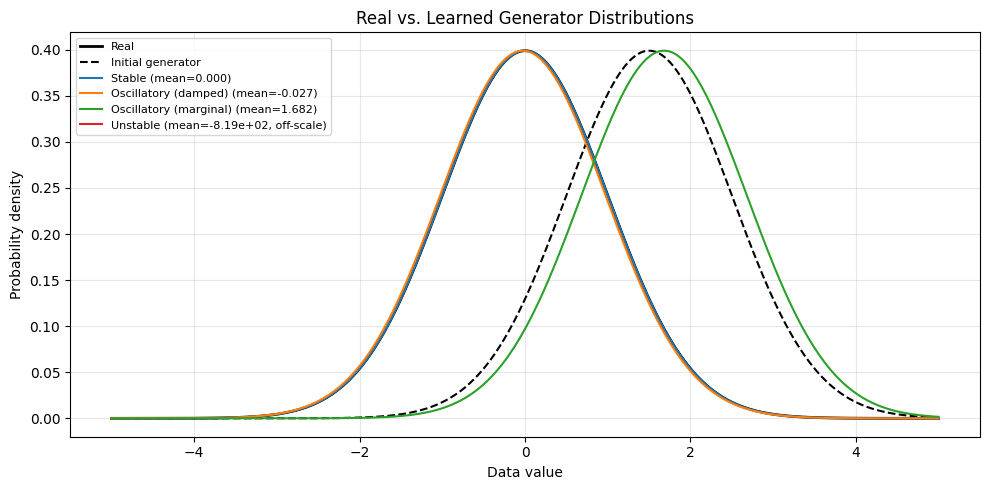

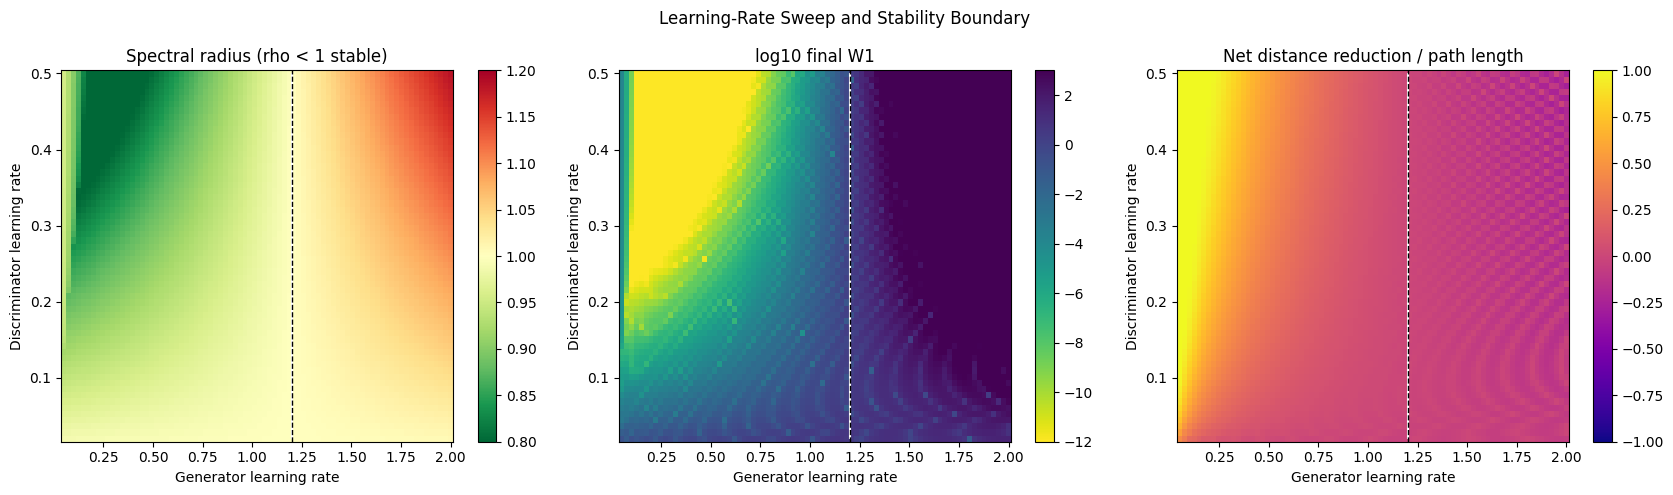


INTERPRETATION

Stable: lr_g=0.08, lr_d=0.1
  Spectral radius: 0.9423
  Initial W1: 1.5000
  Final W1: 3.208e-06
  Path length: 1.7626
  Net efficiency: 0.8510
  Converged within the selected tolerance.

Oscillatory (damped): lr_g=1.0, lr_d=0.2
  Spectral radius: 0.9798
  Initial W1: 1.5000
  Final W1: 2.658e-02
  Path length: 29.2847
  Net efficiency: 0.0503
  Asymptotically stable, but tolerance not reached.

Oscillatory (marginal): lr_g=1.2, lr_d=0.2
  Spectral radius: 1.0000
  Initial W1: 1.5000
  Final W1: 1.682e+00
  Path length: 139.7296
  Net efficiency: -0.0013
  Marginally stable: persistent oscillations are expected.

Unstable: lr_g=1.5, lr_d=0.2
  Spectral radius: 1.0296
  Initial W1: 1.5000
  Final W1: 8.194e+02
  Path length: 9669.7677
  Net efficiency: -0.0846
  Unstable: perturbations grow under repeated updates.

LIMITATION: This is a simplified linear game with a scalar generator and discriminator, not a full neural-network GAN.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import wasserstein_distance

np.random.seed(42)

gamma = 1.2
steps = 200
initial_g, initial_d = 1.5, 0.8
eps = 0.01

real_samples = np.random.normal(0, 1, 10000)
real_mean = 0.0
initial_distance = abs(initial_g - real_mean)


def payoff(g, d):
    return g * d - 0.5 * gamma * d**2


def jacobian(lr_g, lr_d):
    return np.array([
        [1.0, -lr_g],
        [lr_d, 1.0 - lr_d * gamma]
    ])


experiments = {
    "Stable": (0.08, 0.10),
    "Oscillatory (damped)": (1.00, 0.20),
    "Oscillatory (marginal)": (1.20, 0.20),
    "Unstable": (1.50, 0.20)
}

# Run experiments
results = {}

for name, (lr_g, lr_d) in experiments.items():
    g, d = initial_g, initial_d
    means, discs = [g], [d]

    for _ in range(steps):
        next_g = g - lr_g * d
        next_d = d + lr_d * (g - gamma * d)
        g, d = next_g, next_d
        means.append(g)
        discs.append(d)

    means = np.array(means)
    discs = np.array(discs)
    distances = np.abs(means - real_mean)

    path_len = np.sum(np.abs(np.diff(means)))
    efficiency = (
        (distances[0] - distances[-1]) / path_len
        if path_len > 1e-12 else 0.0
    )

    eigvals = np.linalg.eigvals(jacobian(lr_g, lr_d))
    rho = np.max(np.abs(eigvals))

    below = np.where(distances < eps)[0]
    conv_time = int(below[0]) if len(below) else None

    overshoots = int(np.sum(np.diff(np.sign(means)) != 0))

    check_idx = [0, 50, 100, 200]
    emp_err = max(
        abs(
            wasserstein_distance(
                real_samples, real_samples + means[t]
            ) - distances[t]
        )
        for t in check_idx
    )

    results[name] = {
        "means": means,
        "discs": discs,
        "distances": distances,
        "path": path_len,
        "efficiency": efficiency,
        "eig": eigvals,
        "rho": rho,
        "conv_time": conv_time,
        "overshoots": overshoots,
        "emp_err": emp_err,
        "lr_g": lr_g,
        "lr_d": lr_d
    }

# Numerical results
print("GAN GAME DYNAMICS: EXPERIMENTAL RESULTS")
print(f"Payoff: V(g,d) = gd - (gamma/2)d^2, gamma = {gamma}")
print("Equilibrium: (g*, d*) = (0, 0)")
print("-" * 112)
print(
    f"{'Regime':<24}{'lr_g':>7}{'lr_d':>7}{'rho':>9}"
    f"{'Final W1':>13}{'Path len':>13}{'Efficiency':>12}"
    f"{'Conv iter':>12}{'Crossings':>11}"
)
print("-" * 112)

for name, r in results.items():
    ct = str(r["conv_time"]) if r["conv_time"] is not None else "never"
    print(
        f"{name:<24}{r['lr_g']:>7.2f}{r['lr_d']:>7.2f}"
        f"{r['rho']:>9.4f}{r['distances'][-1]:>13.3e}"
        f"{r['path']:>13.4f}{r['efficiency']:>12.4f}"
        f"{ct:>12}{r['overshoots']:>11d}"
    )

print("\nEigenvalues of the update matrix:")
for name, r in results.items():
    print(f"{name:<24}{np.round(r['eig'], 4)} |lambda|max = {r['rho']:.4f}")

print("\nAnalytic vs shared-sample empirical W1 maximum error:")
for name, r in results.items():
    print(f"{name:<24}{r['emp_err']:.2e}")

# Wasserstein distance
plt.figure(figsize=(10, 5))
for name, r in results.items():
    plt.semilogy(r["distances"] + 1e-16, label=name)

plt.axhline(eps, color="gray", linestyle=":", label=f"eps = {eps}")
plt.xlabel("Training iteration")
plt.ylabel("Wasserstein distance W1(Pg, Pr)")
plt.title("Convergence of Generator Distribution")
plt.legend()
plt.grid(alpha=0.3, which="both")
plt.tight_layout()
plt.show()

# Generator trajectory
plt.figure(figsize=(10, 5))
for name, r in results.items():
    plt.plot(r["means"], label=name)

plt.axhline(real_mean, linestyle="--", color="black", label="Real mean")
plt.ylim(-5, 5)
plt.xlabel("Training iteration")
plt.ylabel("Generator mean g")
plt.title("Generator Trajectory Toward the Real Distribution")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Phase portrait
plt.figure(figsize=(7, 6))
for name, r in results.items():
    mask = (np.abs(r["means"]) < 3) & (np.abs(r["discs"]) < 3)
    plt.plot(r["means"][mask], r["discs"][mask], label=name)

plt.scatter([0], [0], marker="*", s=180, color="black", label="Equilibrium")
plt.xlim(-3, 3)
plt.ylim(-3, 3)
plt.xlabel("Generator parameter g")
plt.ylabel("Discriminator parameter d")
plt.title("Phase Portrait of Game Dynamics")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Distribution comparison
x = np.linspace(-5, 5, 500)


def normal_pdf(x, mu):
    return np.exp(-0.5 * (x - mu)**2) / np.sqrt(2 * np.pi)


plt.figure(figsize=(10, 5))
plt.plot(x, normal_pdf(x, real_mean), "k", linewidth=2, label="Real")
plt.plot(x, normal_pdf(x, initial_g), "k--", label="Initial generator")

for name, r in results.items():
    mu = r["means"][-1]
    if abs(mu) < 4:
        plt.plot(x, normal_pdf(x, mu), label=f"{name} (mean={mu:.3f})")
    else:
        plt.plot([], [], label=f"{name} (mean={mu:.2e}, off-scale)")

plt.xlabel("Data value")
plt.ylabel("Probability density")
plt.title("Real vs. Learned Generator Distributions")
plt.legend(fontsize=8)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Learning-rate sweep
lr_g_grid = np.linspace(0.05, 2.0, 80)
lr_d_grid = np.linspace(0.02, 0.5, 60)
LG, LD = np.meshgrid(lr_g_grid, lr_d_grid)

g = np.full_like(LG, initial_g)
d = np.full_like(LG, initial_d)
path = np.zeros_like(LG)

for _ in range(steps):
    ng = g - LG * d
    nd = d + LD * (g - gamma * d)
    path += np.abs(ng - g)
    g, d = ng, nd

final_W1 = np.abs(g - real_mean)
eff = (initial_distance - final_W1) / np.maximum(path, 1e-12)

tr = 2.0 - LD * gamma
det = 1.0 - LD * gamma + LG * LD
disc = tr**2 - 4 * det
sq = np.sqrt(np.maximum(disc, 0))

rho = np.where(
    disc < 0,
    np.sqrt(np.maximum(det, 0)),
    np.maximum(np.abs(tr + sq), np.abs(tr - sq)) / 2
)

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

panels = [
    (rho, "Spectral radius (rho < 1 stable)", "RdYlGn_r", 0.8, 1.2),
    (np.clip(np.log10(final_W1 + 1e-16), -12, 3),
     "log10 final W1", "viridis_r", -12, 3),
    (eff, "Net distance reduction / path length", "plasma", -1, 1)
]

for ax, (Z, title, cmap, lo, hi) in zip(axes, panels):
    im = ax.pcolormesh(
        LG, LD, Z, cmap=cmap, vmin=lo, vmax=hi, shading="auto"
    )
    ax.contour(LG, LD, rho, levels=[1.0], colors="white", linewidths=1.5)
    ax.axvline(gamma, color="black", linestyle="--", linewidth=1)
    ax.set_xlabel("Generator learning rate")
    ax.set_ylabel("Discriminator learning rate")
    ax.set_title(title)
    fig.colorbar(im, ax=ax)

plt.suptitle("Learning-Rate Sweep and Stability Boundary")
plt.tight_layout()
plt.show()

# Interpretation
print("\nINTERPRETATION")

for name, r in results.items():
    print(f"\n{name}: lr_g={r['lr_g']}, lr_d={r['lr_d']}")
    print(f"  Spectral radius: {r['rho']:.4f}")
    print(f"  Initial W1: {r['distances'][0]:.4f}")
    print(f"  Final W1: {r['distances'][-1]:.3e}")
    print(f"  Path length: {r['path']:.4f}")
    print(f"  Net efficiency: {r['efficiency']:.4f}")

    if np.isclose(r["rho"], 1.0, atol=1e-9):
        print("  Marginally stable: persistent oscillations are expected.")
    elif r["rho"] < 1 and r["distances"][-1] < eps:
        print("  Converged within the selected tolerance.")
    elif r["rho"] < 1:
        print("  Asymptotically stable, but tolerance not reached.")
    else:
        print("  Unstable: perturbations grow under repeated updates.")

print(
    "\nLIMITATION: This is a simplified linear game with a scalar "
    "generator and discriminator, not a full neural-network GAN."
)

noise floor W1(real512, real512') = 1.372 +- 0.009
regime runs done in 783s
sweep done in 876s


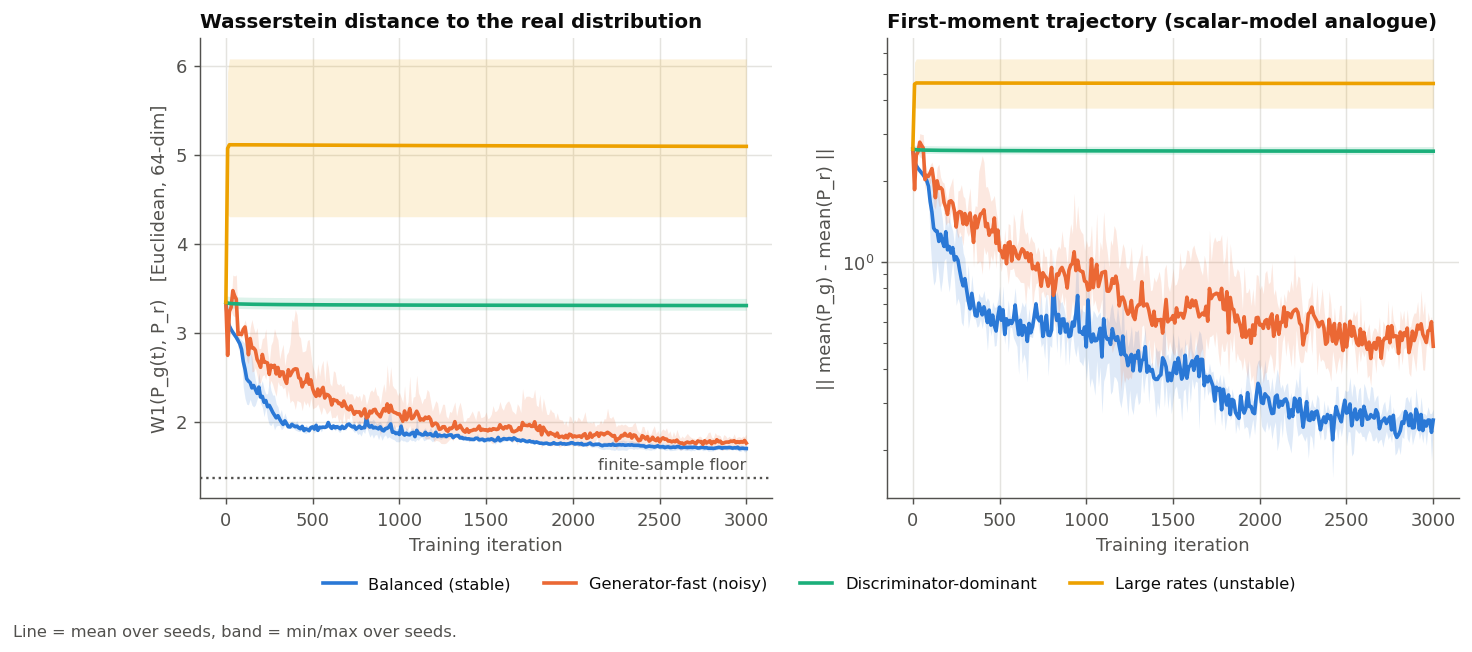

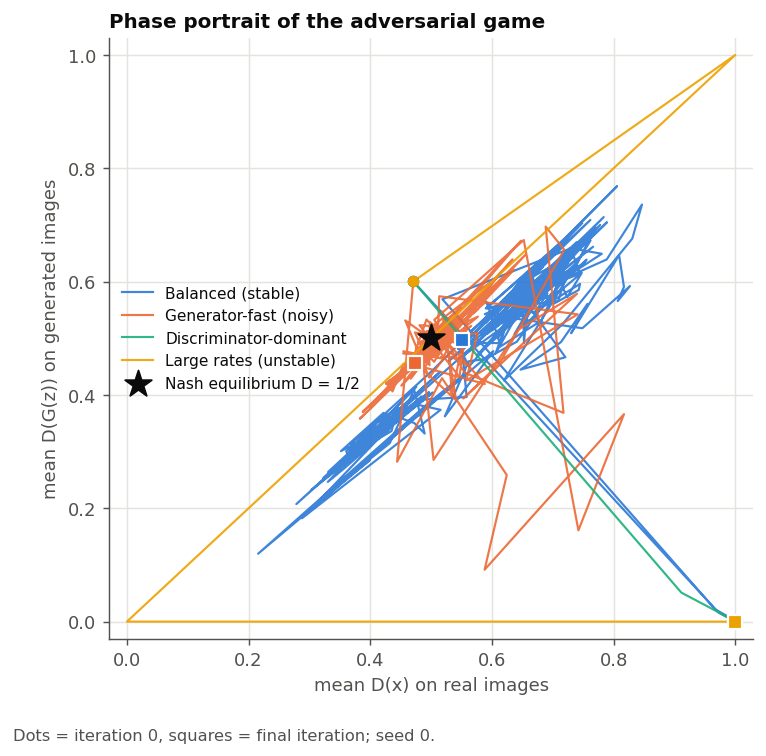

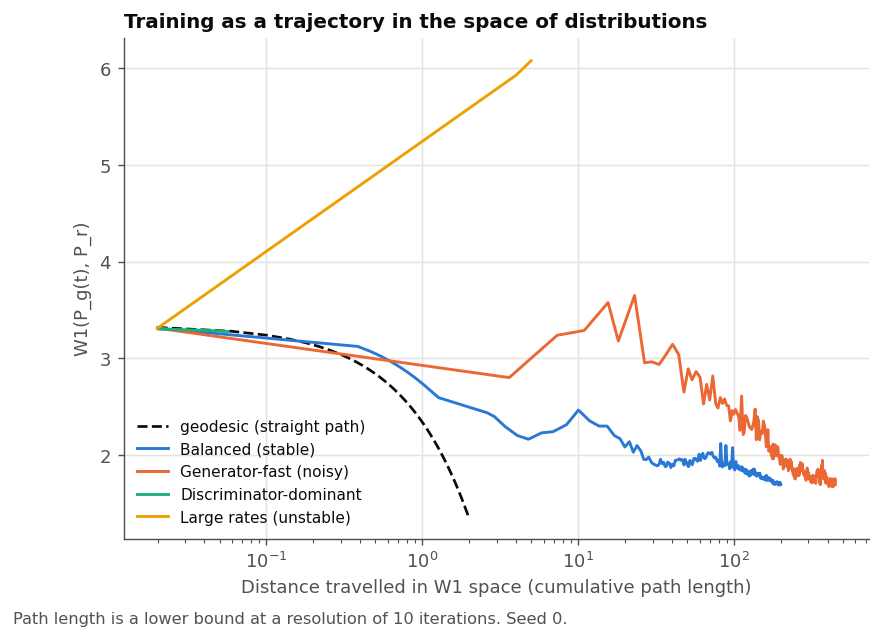

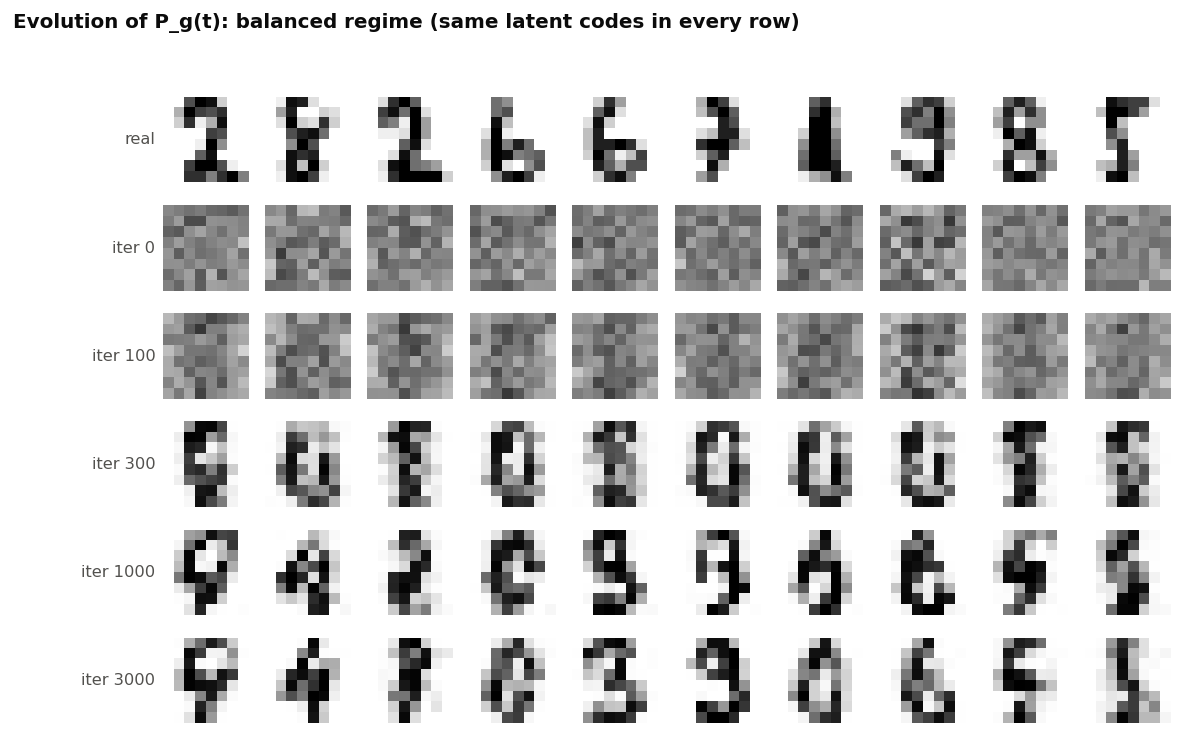

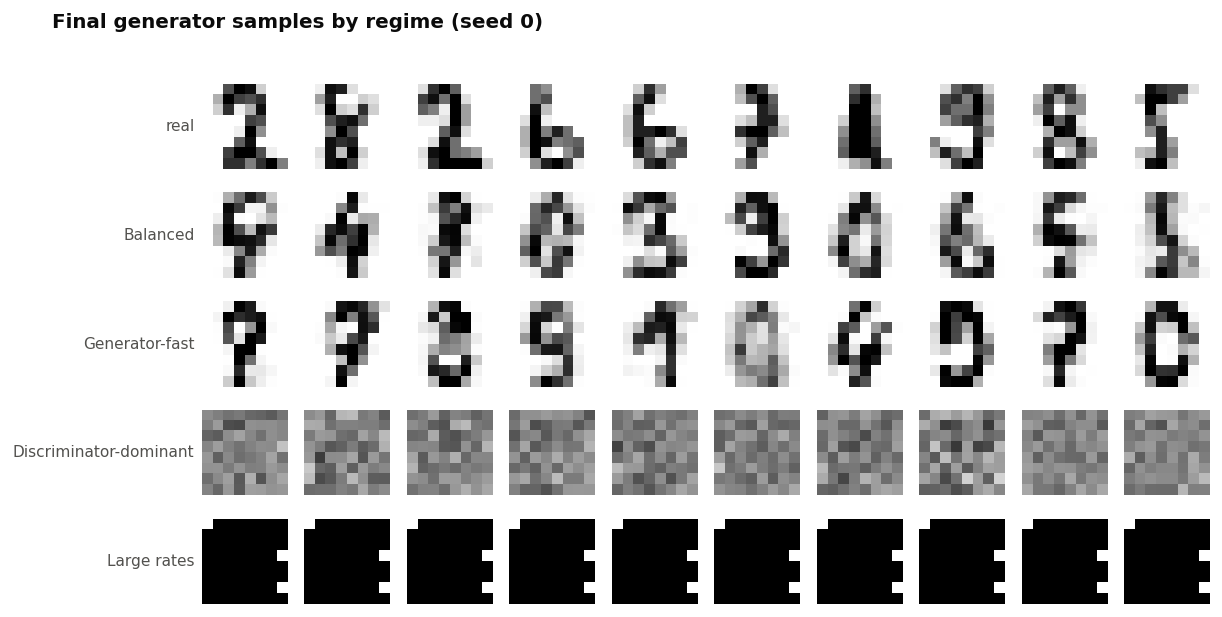

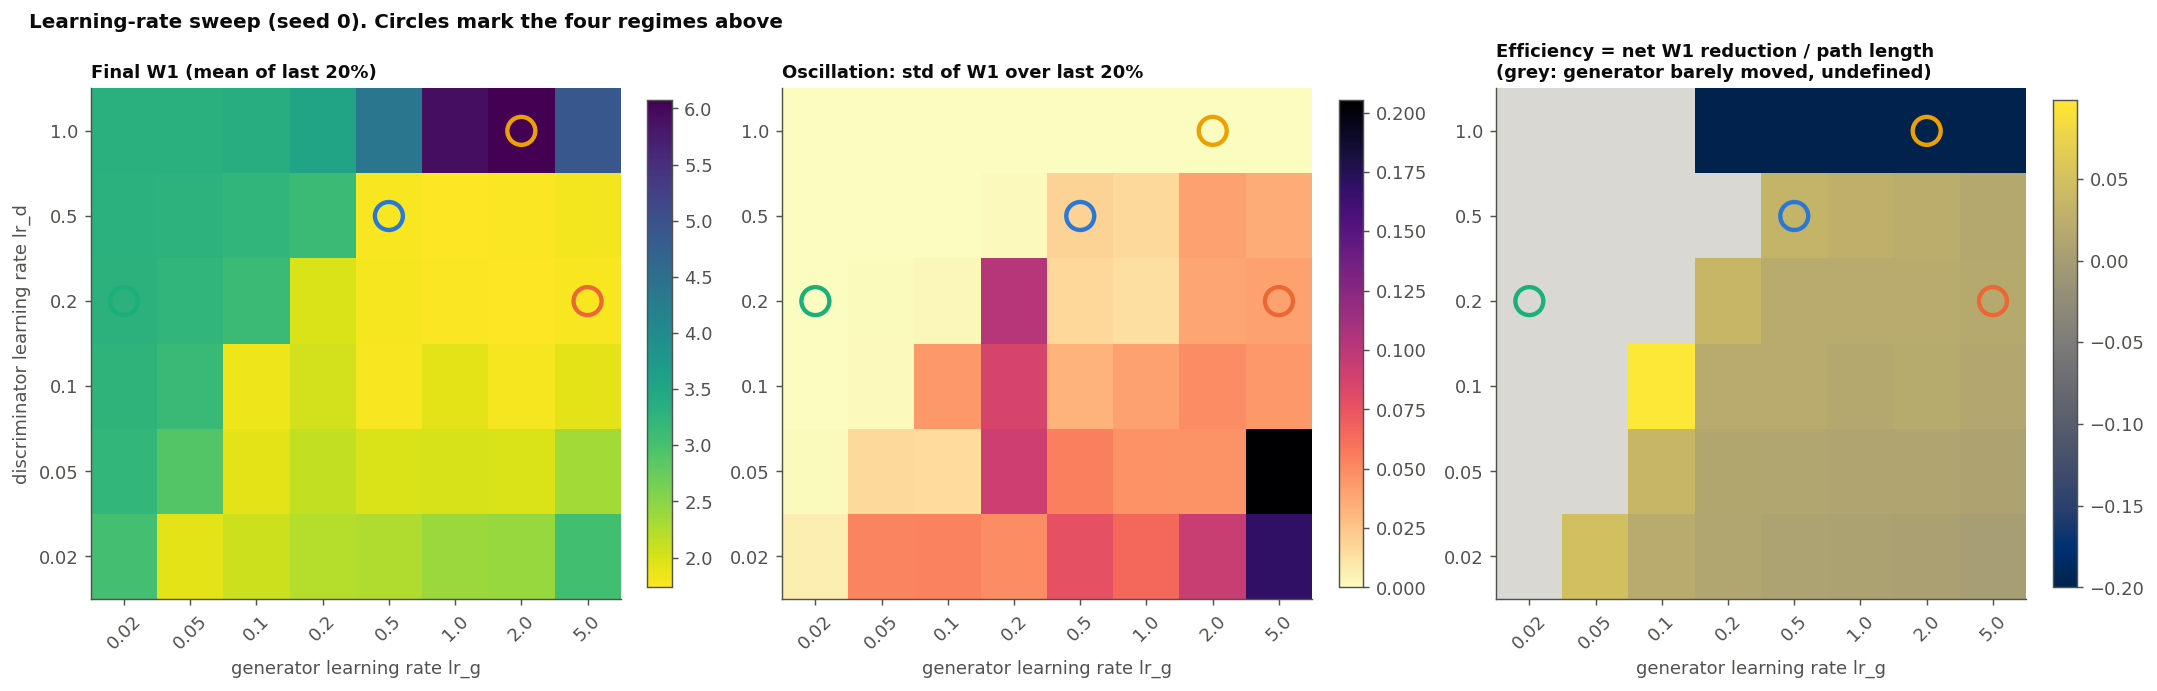


IMAGE GAN: RESULTS (mean +- std over 3 seeds, 3000 iterations)
Initial W1 ~ 3.339   finite-sample noise floor = 1.372
------------------------------------------------------------------------------------------------------------------------
Regime                      lr_g  lr_d        Final W1      Tail std        Path len      Efficiency   Diversity  Settled
------------------------------------------------------------------------------------------------------------------------
Balanced (stable)            0.5   0.5    1.697+-0.025  0.010+-0.002     197.6+-12.3  0.0084+-0.0009        0.98      3/3
Generator-fast (noisy)       5.0   0.2    1.759+-0.072  0.036+-0.004     457.1+-33.6  0.0035+-0.0003        0.92      2/3
Discriminator-dominant      0.02   0.2    3.304+-0.058  0.000+-0.000        0.1+-0.0 n/a (no motion)        0.31      0/3
Large rates (unstable)       2.0   1.0    5.093+-0.737  0.001+-0.001        4.5+-0.4 -0.3808+-0.1360        0.06      0/3


In [1]:
"""
GAN game dynamics on images (8x8 grayscale digits) - single-file version.

    python gan_images_game.py            # full run (~6 min on 2 cores)
    python gan_images_game.py --quick    # smoke test
    python gan_images_game.py --replot   # redraw from outputs/results.pkl

Needs: numpy, scipy, scikit-learn, matplotlib (no PyTorch).
"""

import numpy as np
from sklearn.datasets import load_digits
from scipy.optimize import linear_sum_assignment
from scipy.spatial.distance import cdist

Z_DIM, H_G, H_D, X_DIM = 16, 64, 64, 64


# ----------------------------------------------------------------- data
def load_data(n_eval=512, seed=0):
    X = load_digits().data.astype(np.float64) / 16.0          # 8x8 grey, [0,1]
    rng = np.random.RandomState(seed)
    X = X[rng.permutation(len(X))]
    holdout = X[:n_eval]                                       # reference P_r for W1
    train = X[n_eval:]                                         # what the GAN sees
    return train, holdout


# ----------------------------------------------------------------- networks
def sigmoid(a):
    return 1.0 / (1.0 + np.exp(-np.clip(a, -50, 50)))


def init_params(rng):
    def xavier(i, o):
        return rng.randn(i, o) * np.sqrt(2.0 / (i + o))
    G = dict(W1=xavier(Z_DIM, H_G), b1=np.zeros(H_G),
             W2=xavier(H_G, X_DIM), b2=np.zeros(X_DIM))
    D = dict(W1=xavier(X_DIM, H_D), b1=np.zeros(H_D),
             W2=xavier(H_D, 1), b2=np.zeros(1))
    return G, D


def g_forward(G, z):
    a1 = z @ G["W1"] + G["b1"]
    h1 = np.maximum(a1, 0.0)
    x = sigmoid(h1 @ G["W2"] + G["b2"])
    return x, (z, a1, h1, x)


def d_forward(D, x):
    a1 = x @ D["W1"] + D["b1"]
    h = np.where(a1 > 0, a1, 0.2 * a1)
    logit = h @ D["W2"] + D["b2"]
    return logit, (x, a1, h)


def d_backward(D, cache, dlogit):
    x, a1, h = cache
    grads = {"W2": h.T @ dlogit, "b2": dlogit.sum(0)}
    da1 = (dlogit @ D["W2"].T) * np.where(a1 > 0, 1.0, 0.2)
    grads["W1"] = x.T @ da1
    grads["b1"] = da1.sum(0)
    dx = da1 @ D["W1"].T
    return grads, dx


def g_backward(G, cache, dx):
    z, a1, h1, x = cache
    da2 = dx * x * (1.0 - x)
    grads = {"W2": h1.T @ da2, "b2": da2.sum(0)}
    da1 = (da2 @ G["W2"].T) * (a1 > 0)
    grads["W1"] = z.T @ da1
    grads["b1"] = da1.sum(0)
    return grads


# ----------------------------------------------------------------- geometry
def w1_empirical(A, B):
    """Exact W1 between equal-size uniform empirical measures (Euclidean cost)."""
    C = cdist(A, B)
    r, c = linear_sum_assignment(C)
    return C[r, c].mean()


def mean_pdist(A):
    return cdist(A, A).sum() / (len(A) * (len(A) - 1))


# ----------------------------------------------------------------- training
def train(lr_g, lr_d, seed, iters, train_x, holdout, z_eval,
          batch=128, eval_every=10, generator_loss="minimax", snap_its=()):
    """Simultaneous SGD on the GAN game; logs distribution-space quantities.

    generator_loss: 'minimax'   -> true zero-sum game  (G minimises log(1-D(G(z))))
                    'nonsat'    -> common heuristic    (G minimises -log D(G(z)))
    """
    rng = np.random.RandomState(seed)
    G, D = init_params(rng)
    div_real = mean_pdist(holdout)

    log = {k: [] for k in ["it", "w1", "step", "mean_err", "d_real", "d_fake",
                           "div", "gnorm", "dnorm"]}
    prev_fake = None
    diverged = False

    def record(it, gn, dn):
        nonlocal prev_fake
        fake, _ = g_forward(G, z_eval)
        lr_, _ = d_forward(D, holdout)
        lf_, _ = d_forward(D, fake)
        log["it"].append(it)
        log["w1"].append(w1_empirical(fake, holdout))
        log["step"].append(0.0 if prev_fake is None else w1_empirical(fake, prev_fake))
        log["mean_err"].append(np.linalg.norm(fake.mean(0) - holdout.mean(0)))
        log["d_real"].append(sigmoid(lr_).mean())
        log["d_fake"].append(sigmoid(lf_).mean())
        log["div"].append(mean_pdist(fake) / div_real)
        log["gnorm"].append(gn)
        log["dnorm"].append(dn)
        prev_fake = fake

    snaps = {}
    if 0 in snap_its:
        snaps[0] = g_forward(G, z_eval[:10])[0]
    record(0, 0.0, 0.0)
    gn = dn = 0.0
    for it in range(1, iters + 1):
        xr = train_x[rng.randint(0, len(train_x), batch)]
        z = rng.randn(batch, Z_DIM)

        # forward
        xf, gc = g_forward(G, z)
        lr_, rc = d_forward(D, xr)
        lf_, fc = d_forward(D, xf)
        pr, pf = sigmoid(lr_), sigmoid(lf_)

        # discriminator gradients (descent on -V  == ascent on V)
        gD_r, _ = d_backward(D, rc, (pr - 1.0) / batch)
        gD_f, dx_unused = d_backward(D, fc, pf / batch)
        gD = {k: gD_r[k] + gD_f[k] for k in gD_r}

        # generator gradients through the SAME (pre-update) discriminator
        if generator_loss == "minimax":
            dl = -pf / batch                       # d/dlogit of  mean log(1 - D(G(z)))
        else:
            dl = (pf - 1.0) / batch                # d/dlogit of -mean log D(G(z))
        _, dx = d_backward(D, fc, dl)
        gG = g_backward(G, gc, dx)

        # simultaneous update
        for k in G:
            G[k] -= lr_g * gG[k]
        for k in D:
            D[k] -= lr_d * gD[k]

        if not all(np.all(np.isfinite(v)) for v in list(G.values()) + list(D.values())):
            diverged = True
            break

        if it in snap_its:
            snaps[it] = g_forward(G, z_eval[:10])[0]

        if it % eval_every == 0:
            gn = np.sqrt(sum((v ** 2).sum() for v in gG.values()))
            dn = np.sqrt(sum((v ** 2).sum() for v in gD.values()))
            record(it, gn, dn)

    out = {k: np.array(v) for k, v in log.items()}
    out["diverged"] = diverged
    out["snaps"] = snaps
    return out


def summarise(out, floor, eps_factor=1.25):
    """Scalar-model quantities, computed from the logged trajectory."""
    w1 = out["w1"]
    path = out["step"].sum()                       # polyline length in W1 space
    net = w1[0] - w1[-1]
    eff = net / path if path > 1e-12 else 0.0
    tail = w1[int(0.8 * len(w1)):]                 # last 20% of training
    thr = eps_factor * floor
    below = np.where(w1 < thr)[0]
    inside_after = np.where(w1 >= thr)[0]
    if len(inside_after) == 0:
        settle = 0
    elif inside_after[-1] == len(w1) - 1:
        settle = None
    else:
        settle = int(out["it"][inside_after[-1] + 1])
    # oscillation: sign changes of the detrended-by-smoothing W1 increments
    d = np.diff(w1)
    sm = np.convolve(d, np.ones(5) / 5, mode="same")
    osc = int(np.sum(np.diff(np.sign(sm[np.abs(sm) > 1e-9])) != 0))
    return dict(final_w1=float(w1[-1]), best_w1=float(w1.min()),
                tail_std=float(tail.std()), path=float(path), eff=float(eff),
                settle=settle, osc=osc, div=float(out["div"][-1]),
                diverged=bool(out["diverged"]))


# ======================================================================
# Experiments, tables and figures
# ======================================================================
import os, sys, time, pickle, argparse, csv
from multiprocessing import Pool
import numpy as np
import matplotlib
try:
    get_ipython()                      # running in Jupyter/Colab: keep inline backend
    IN_NOTEBOOK = True
except NameError:
    matplotlib.use("Agg")              # plain script: no display needed
    IN_NOTEBOOK = False
import matplotlib.pyplot as plt

# ---------------------------------------------------------------- settings
OUT = "outputs"
SEEDS = [0, 1, 2]
ITERS, EVAL_EVERY = 3000, 10
SNAP_ITS = (0, 100, 300, 1000, 3000)
SWEEP_G = [0.02, 0.05, 0.1, 0.2, 0.5, 1.0, 2.0, 5.0]
SWEEP_D = [0.02, 0.05, 0.1, 0.2, 0.5, 1.0]
SWEEP_ITERS, SWEEP_EVAL = 2000, 40
TOL_FACTOR = 1.35                      # "settled" = W1 stays below 1.35 x noise floor

# regime name -> (lr_g, lr_d); colours follow a fixed categorical order
REGIMES = {
    "Balanced (stable)":        (0.5, 0.5),
    "Generator-fast (noisy)":   (5.0, 0.2),
    "Discriminator-dominant":   (0.02, 0.2),
    "Large rates (unstable)":   (2.0, 1.0),
}
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"

plt.rcParams.update({
    "figure.dpi": 130, "savefig.dpi": 160, "axes.spines.top": False,
    "axes.spines.right": False, "axes.edgecolor": INK2, "axes.labelcolor": INK2,
    "xtick.color": INK2, "ytick.color": INK2, "text.color": INK,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "legend.frameon": False, "font.size": 10, "axes.axisbelow": True,
})

TRAIN_X, HOLDOUT = load_data()
Z_EVAL = np.random.RandomState(12345).randn(512, Z_DIM)


def noise_floor():
    """W1 between two independent 512-image samples of REAL data (finite-sample floor)."""
    rs = np.random.RandomState(7)
    v = [w1_empirical(TRAIN_X[rs.choice(len(TRAIN_X), 512, replace=False)], HOLDOUT)
         for _ in range(5)]
    return float(np.mean(v)), float(np.std(v))


def regime_job(a):
    name, lr_g, lr_d, seed, iters = a
    o = train(lr_g, lr_d, seed, iters, TRAIN_X, HOLDOUT, Z_EVAL,
              eval_every=EVAL_EVERY, snap_its=SNAP_ITS)
    return name, seed, o


def sweep_job(a):
    lr_g, lr_d, iters = a
    o = train(lr_g, lr_d, 0, iters, TRAIN_X, HOLDOUT, Z_EVAL, eval_every=SWEEP_EVAL)
    return lr_g, lr_d, o


# ---------------------------------------------------------------- experiments
def run_experiments(quick):
    iters = 400 if quick else ITERS
    seeds = SEEDS[:1] if quick else SEEDS
    floor, floor_sd = noise_floor()
    print(f"noise floor W1(real512, real512') = {floor:.3f} +- {floor_sd:.3f}")

    jobs = [(n, lg, ld, s, iters) for n, (lg, ld) in REGIMES.items() for s in seeds]
    t = time.time()
    with Pool(2) as p:
        runs = p.map(regime_job, jobs)
    print(f"regime runs done in {time.time() - t:.0f}s")

    sg, sd = (SWEEP_G[::3], SWEEP_D[::3]) if quick else (SWEEP_G, SWEEP_D)
    sw_iters = 400 if quick else SWEEP_ITERS
    t = time.time()
    with Pool(2) as p:
        sweep = p.map(sweep_job, [(g, d, sw_iters) for g in sg for d in sd])
    print(f"sweep done in {time.time() - t:.0f}s")

    res = dict(floor=floor, floor_sd=floor_sd, runs=runs, sweep=sweep,
               sweep_g=sg, sweep_d=sd, iters=iters, seeds=seeds)
    os.makedirs(OUT, exist_ok=True)
    pickle.dump(res, open(f"{OUT}/results.pkl", "wb"))
    return res


# ---------------------------------------------------------------- tables
def table(res):
    floor = res["floor"]
    rows = []
    for name, (lg, ld) in REGIMES.items():
        S = [summarise(o, floor, TOL_FACTOR) for n, s, o in res["runs"] if n == name]
        def ms(k):
            v = np.array([x[k] for x in S], float)
            return v.mean(), v.std()
        settle = [x["settle"] for x in S]
        rows.append(dict(
            regime=name, lr_g=lg, lr_d=ld,
            final_w1=ms("final_w1"), tail_std=ms("tail_std"), path=ms("path"),
            eff=ms("eff"), div=ms("div"),
            settled=f"{sum(s is not None for s in settle)}/{len(settle)}",
            settle_it=(np.mean([s for s in settle if s is not None])
                       if any(s is not None for s in settle) else None)))
    return rows


def print_and_save_table(rows, res):
    floor = res["floor"]
    print(f"\nIMAGE GAN: RESULTS (mean +- std over {len(res['seeds'])} seeds, "
          f"{res['iters']} iterations)")
    print(f"Initial W1 ~ {np.mean([o['w1'][0] for n, s, o in res['runs']]):.3f}   "
          f"finite-sample noise floor = {floor:.3f}")
    print("-" * 120)
    print(f"{'Regime':<26}{'lr_g':>6}{'lr_d':>6}{'Final W1':>16}{'Tail std':>14}"
          f"{'Path len':>16}{'Efficiency':>16}{'Diversity':>12}{'Settled':>9}")
    print("-" * 120)
    for r in rows:
        f = lambda k, d=3: f"{r[k][0]:.{d}f}+-{r[k][1]:.{d}f}"
        eff_txt = "n/a (no motion)" if r["path"][0] < 1.0 else f("eff", 4)
        print(f"{r['regime']:<26}{r['lr_g']:>6}{r['lr_d']:>6}{f('final_w1'):>16}"
              f"{f('tail_std'):>14}{f('path', 1):>16}{eff_txt:>16}"
              f"{r['div'][0]:>12.2f}{r['settled']:>9}")
    with open(f"{OUT}/results_table.csv", "w", newline="") as fh:
        w = csv.writer(fh)
        w.writerow(["regime", "lr_g", "lr_d", "final_w1_mean", "final_w1_std",
                    "tail_std_mean", "path_mean", "path_std", "efficiency_mean",
                    "efficiency_std", "diversity_ratio", "seeds_settled", "mean_settle_iter"])
        for r in rows:
            w.writerow([r["regime"], r["lr_g"], r["lr_d"], *r["final_w1"],
                        r["tail_std"][0], *r["path"], *r["eff"], r["div"][0],
                        r["settled"], r["settle_it"]])


# ---------------------------------------------------------------- figures
def by_regime(res, name):
    return [o for n, s, o in res["runs"] if n == name]


def save(fig, name):
    fig.savefig(f"{OUT}/{name}.png", bbox_inches="tight")
    if IN_NOTEBOOK:
        plt.show()
    plt.close(fig)


def fig_convergence(res):
    fig, ax = plt.subplots(1, 2, figsize=(12.5, 4.6))
    for (name, _), c in zip(REGIMES.items(), COLORS):
        runs = by_regime(res, name)
        it = runs[0]["it"]
        for key, a in (("w1", ax[0]), ("mean_err", ax[1])):
            M = np.array([o[key] for o in runs])
            a.plot(it, M.mean(0), color=c, lw=2, label=name)
            if len(runs) > 1:
                a.fill_between(it, M.min(0), M.max(0), color=c, alpha=0.15, lw=0)
    ax[0].axhline(res["floor"], color=INK2, ls=":", lw=1.3)
    ax[0].text(it[-1], res["floor"] + 0.06, "finite-sample floor", ha="right",
               va="bottom", color=INK2, fontsize=9)
    ax[0].set_ylabel("W1(P_g(t), P_r)   [Euclidean, 64-dim]")
    ax[0].set_title("Wasserstein distance to the real distribution")
    ax[1].set_yscale("log")
    ax[1].set_ylabel("|| mean(P_g) - mean(P_r) ||")
    ax[1].set_title("First-moment trajectory (scalar-model analogue)")
    for a in ax:
        a.set_xlabel("Training iteration")
    h, l = ax[0].get_legend_handles_labels()
    fig.legend(h, l, loc="lower center", ncol=4, fontsize=9, bbox_to_anchor=(0.5, -0.07))
    fig.text(0.01, -0.12, "Line = mean over seeds, band = min/max over seeds.", color=INK2, fontsize=9)
    save(fig, "fig1_convergence")


def fig_phase(res):
    fig, ax = plt.subplots(figsize=(6.4, 6))
    for (name, _), c in zip(REGIMES.items(), COLORS):
        o = by_regime(res, name)[0]
        ax.plot(o["d_real"], o["d_fake"], color=c, lw=1.2, alpha=0.9, label=name)
        ax.scatter(o["d_real"][0], o["d_fake"][0], color=c, s=28, zorder=3)
        ax.scatter(o["d_real"][-1], o["d_fake"][-1], color=c, s=60, marker="s",
                   edgecolor="white", linewidth=1.2, zorder=5)
    ax.scatter([0.5], [0.5], marker="*", s=240, color=INK, zorder=4, label="Nash equilibrium D = 1/2")
    ax.set_xlim(-0.03, 1.03); ax.set_ylim(-0.03, 1.03)
    ax.set_xlabel("mean D(x) on real images"); ax.set_ylabel("mean D(G(z)) on generated images")
    ax.set_title("Phase portrait of the adversarial game")
    ax.legend(loc="center left", fontsize=8.5)
    fig.text(0.01, -0.02, "Dots = iteration 0, squares = final iteration; seed 0.", color=INK2, fontsize=9)
    save(fig, "fig2_phase_portrait")


def fig_geometry(res):
    fig, ax = plt.subplots(figsize=(7.4, 5))
    w0 = np.mean([o["w1"][0] for n, s, o in res["runs"]])
    xs = np.linspace(0.02, w0 - res["floor"], 50)
    ax.plot(xs, w0 - xs, color=INK, ls="--", lw=1.5, label="geodesic (straight path)")
    for (name, _), c in zip(REGIMES.items(), COLORS):
        o = by_regime(res, name)[0]
        s = np.cumsum(o["step"])
        ax.plot(np.maximum(s, 0.02), o["w1"], color=c, lw=1.6, label=name)
    ax.set_xscale("log")
    ax.set_xlabel("Distance travelled in W1 space (cumulative path length)")
    ax.set_ylabel("W1(P_g(t), P_r)")
    ax.set_title("Training as a trajectory in the space of distributions")
    ax.legend(fontsize=8.5, loc="lower left")
    fig.text(0.01, -0.02, "Path length is a lower bound at a resolution of 10 iterations. Seed 0.", color=INK2, fontsize=9)
    save(fig, "fig3_trajectory_geometry")


def fig_images(res):
    cols = len(SNAP_ITS)
    # (a) evolution of the balanced regime
    o = by_regime(res, "Balanced (stable)")[0]
    its = [i for i in SNAP_ITS if i in o["snaps"]]
    fig, axs = plt.subplots(len(its) + 1, 10, figsize=(10, 1.05 * (len(its) + 1)))
    rows = [("real", HOLDOUT[:10])] + [(f"iter {i}", o["snaps"][i]) for i in its]
    for r, (lab, imgs) in enumerate(rows):
        for c in range(10):
            a = axs[r, c]; a.imshow(imgs[c].reshape(8, 8), cmap="gray_r", vmin=0, vmax=1)
            a.set_xticks([]); a.set_yticks([]); a.grid(False)
            for s in a.spines.values(): s.set_visible(False)
        axs[r, 0].set_ylabel(lab, rotation=0, ha="right", va="center", fontsize=9)
    fig.suptitle("Evolution of P_g(t): balanced regime (same latent codes in every row)", x=0.01, ha="left", fontsize=11, fontweight="bold")
    save(fig, "fig4_samples_evolution")

    # (b) final samples per regime
    fig, axs = plt.subplots(len(REGIMES) + 1, 10, figsize=(10, 1.05 * (len(REGIMES) + 1)))
    rows = [("real", HOLDOUT[:10])] + [(n.split(" (")[0], by_regime(res, n)[0]["snaps"][max(SNAP_ITS)] if max(SNAP_ITS) in by_regime(res, n)[0]["snaps"] else by_regime(res, n)[0]["snaps"][max(by_regime(res, n)[0]["snaps"])]) for n in REGIMES]
    for r, (lab, imgs) in enumerate(rows):
        for c in range(10):
            a = axs[r, c]; a.imshow(imgs[c].reshape(8, 8), cmap="gray_r", vmin=0, vmax=1)
            a.set_xticks([]); a.set_yticks([]); a.grid(False)
            for s in a.spines.values(): s.set_visible(False)
        axs[r, 0].set_ylabel(lab, rotation=0, ha="right", va="center", fontsize=8.5)
    fig.suptitle("Final generator samples by regime (seed 0)", x=0.01, ha="left", fontsize=11, fontweight="bold")
    save(fig, "fig5_final_samples")


def fig_sweep(res):
    sg, sd = res["sweep_g"], res["sweep_d"]
    shape = (len(sd), len(sg))
    tail_w1 = np.zeros(shape); tail_sd = np.zeros(shape); eff = np.zeros(shape)
    dfake = np.zeros(shape)
    for lg, ld, o in res["sweep"]:
        i, j = sd.index(ld), sg.index(lg)
        k = max(2, int(0.2 * len(o["w1"])))
        tail_w1[i, j] = o["w1"][-k:].mean()
        tail_sd[i, j] = o["w1"][-k:].std()
        p = o["step"].sum()
        eff[i, j] = (o["w1"][0] - o["w1"][-1]) / p if p >= 1.0 else np.nan  # no motion -> undefined
        dfake[i, j] = o["d_fake"][-1]
    panels = [
        (tail_w1, "Final W1 (mean of last 20%)", "viridis_r", None, None),
        (tail_sd, "Oscillation: std of W1 over last 20%", "magma_r", 0, None),
        (eff, "Efficiency = net W1 reduction / path length\n(grey: generator barely moved, undefined)", "cividis", -0.2, None),
    ]
    fig, axs = plt.subplots(1, 3, figsize=(16.5, 5.2), constrained_layout=True)
    for k, (a, (Z, title, cmap, lo, hi)) in enumerate(zip(axs, panels)):
        cm = plt.get_cmap(cmap).copy(); cm.set_bad("#d9d8d3")
        im = a.imshow(np.ma.masked_invalid(Z), origin="lower", cmap=cm, vmin=lo, vmax=hi, aspect="auto")
        a.set_xticks(range(len(sg))); a.set_xticklabels([str(x) for x in sg], rotation=45)
        a.set_yticks(range(len(sd))); a.set_yticklabels([str(x) for x in sd])
        a.set_xlabel("generator learning rate lr_g")
        if k == 0:
            a.set_ylabel("discriminator learning rate lr_d")
        a.set_title(title, fontsize=10); a.grid(False)
        fig.colorbar(im, ax=a, fraction=0.046)
        for (n, (lg, ld)), c in zip(REGIMES.items(), COLORS):
            if lg in sg and ld in sd:
                a.scatter(sg.index(lg), sd.index(ld), facecolor="none", edgecolor=c, s=240, lw=2.4)
    fig.suptitle("Learning-rate sweep (seed 0). Circles mark the four regimes above", x=0.01, ha="left", fontsize=11, fontweight="bold")
    save(fig, "fig6_learning_rate_sweep")


def make_figures(res):
    fig_convergence(res); fig_phase(res); fig_geometry(res)
    fig_images(res); fig_sweep(res)
    rows = table(res)
    print_and_save_table(rows, res)


if __name__ == "__main__":
    ap = argparse.ArgumentParser()
    ap.add_argument("--quick", action="store_true")
    ap.add_argument("--replot", action="store_true")
    args, _ = ap.parse_known_args()      # ignore Colab/Jupyter's own -f argument
    if args.replot:
        res = pickle.load(open(f"{OUT}/results.pkl", "rb"))
    else:
        res = run_experiments(args.quick)
    make_figures(res)
